# Blending a regional and a global surface-forcing product

ERA5 covers the globe at ~28 km. Over North America, CONUS404 offers 4 km hourly fields, but only inside its footprint (see [Creating surface forcing](surface_forcing.ipynb#Higher-resolution-over-North-America:-CONUS404)). A ROMS domain that reaches past that footprint needs both: CONUS404 where it has data, and ERA5 everywhere else.

`roms_tools.blend_surface_forcing` does that combination. It takes two surface-forcing products that are already on the same ROMS grid, a **primary** that is `NaN` where it has no data and a **fallback** that covers the whole grid, and returns one dataset:

* where the primary has a value, it is used;
* everywhere else the fallback is used;
* optionally, the two are averaged across a band inside the primary's footprint, so the switch from one product to the other is not a sharp edge.

This notebook shows the method on a small grid in memory. [Blending saved surface-forcing files](blend_surface_forcing_files.ipynb) shows the same thing for files written to disk, which is how a long run is built.

In [ ]:
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np

from roms_tools import Grid, SurfaceForcing, blend_surface_forcing
from roms_tools.setup.surface_forcing_blend import compute_blend_weights

## A grid that straddles the CONUS404 boundary

This is the small grid from the surface-forcing example: 16 × 16 cells over 700 km, centred at 130° W, 52° N. Along this stretch of coast the northern edge of CONUS404 is close to 53° N, so the boundary runs through the domain.

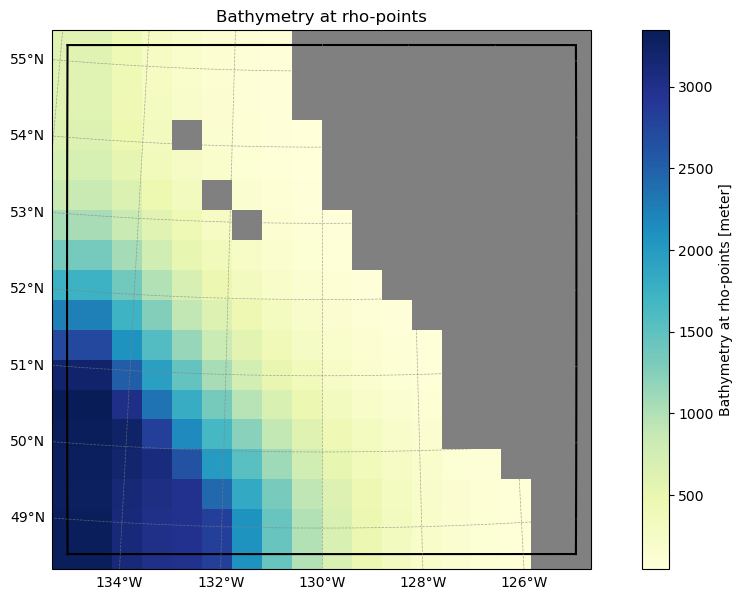

In [ ]:
grid = Grid(
    nx=16,
    ny=16,
    size_x=700,
    size_y=700,
    center_lon=-130,
    center_lat=52,  # straddles the CONUS404 northern limit at this longitude
    rot=0,
)
grid.plot()

## Build the two products

Each product is an ordinary `SurfaceForcing` on the same grid, with the same times. Pass the same explicit `coarse_grid_mode` to both: with the default `"auto"`, ROMS-Tools decides per source from its resolution, so on a 5–15 km grid the 28 km ERA5 can end up on the coarse grid and the 4 km CONUS404 on the fine one, and the two cannot be blended. Each applies its own corrections: the ERA5 radiation correction exists only for ERA5, so it is on for ERA5 and must be off for CONUS404. Both are streamed, so no download is needed (`use_dask=True` is required, and CONUS404 needs the `s3fs` package).

In [ ]:
%%time
common = dict(
    grid=grid,
    start_time=datetime(2020, 6, 15),
    end_time=datetime(2020, 6, 16),
    type="physics",
    coarse_grid_mode="never",  # the same for both products
    use_dask=True,
)
conus404 = SurfaceForcing(
    **common,
    source={"name": "CONUS404"},  # NaN outside its footprint
    correct_radiation=False,  # no correction is defined for CONUS404
)
era5 = SurfaceForcing(
    **common,
    source={"name": "ERA5"},  # covers the whole grid
    correct_radiation=True,
)

2026-11-11 12:41:39 - INFO - No path specified for CONUS404 source; defaulting to the HyTEST zarr store on the USGS/OSN pod (s3://hytest/conus404/conus404_hourly.zarr).
2026-11-11 12:41:46 - INFO - Data will be interpolated onto the fine grid. Remember to set `interp_bulk_frc = .false.` in the `&SURF_FRC_SETTINGS` group of your ROMS `namelist.nml` file.
2026-11-11 12:41:53 - INFO - No path specified for ERA5 source; defaulting to ARCO ERA5 dataset on Google Cloud.
2026-11-11 12:41:54 - INFO - gcsfs experimental features enabled via GCSFS_EXPERIMENTAL_ZB_HNS_SUPPORT.
2026-11-11 12:43:11 - INFO - Data will be interpolated onto the fine grid. Remember to set `interp_bulk_frc = .false.` in the `&SURF_FRC_SETTINGS` group of your ROMS `namelist.nml` file.


CPU times: user 1min 29s, sys: 20.3 s, total: 1min 49s
Wall time: 1min 55s


The maps below show ocean points only. The CONUS404 product is `NaN` in the north of the grid, outside its footprint. Those `NaN`s are deliberate: they tell the blend where to use ERA5 instead. (For the same reason, `SurfaceForcing` does not replace them with zeros, so a CONUS404 product on its own is not ready for ROMS on a grid like this one.)

CONUS404 covers 78% of the grid


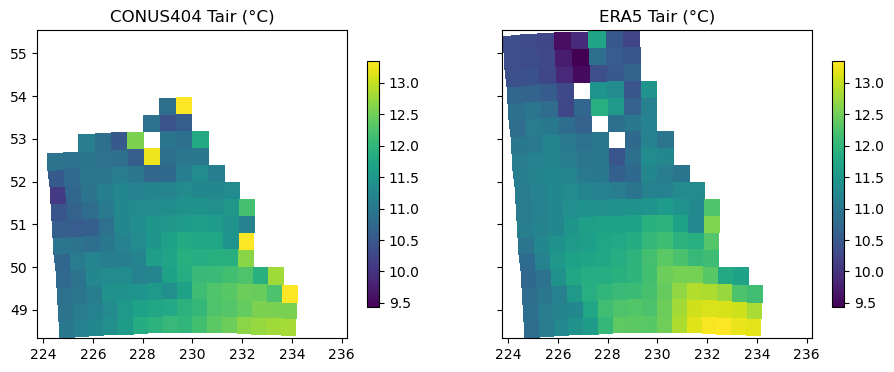

In [ ]:
lon, lat = grid.ds.lon_rho, grid.ds.lat_rho
ocean = grid.ds.mask_rho == 1  # ROMS uses the forcing over the ocean only


def show(ax, da, title, **kw):
    """Map one 2D field over the ocean on the grid's lon/lat."""
    m = ax.pcolormesh(lon, lat, da.where(ocean), shading="auto", **kw)
    ax.set_title(title)
    plt.colorbar(m, ax=ax, shrink=0.8)


tair_c = conus404.ds["Tair"].isel(time=0).compute()
tair_e = era5.ds["Tair"].isel(time=0).compute()
vmin, vmax = float(tair_e.where(ocean).min()), float(tair_e.where(ocean).max())

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
show(axs[0], tair_c, "CONUS404 Tair (°C)", vmin=vmin, vmax=vmax)
show(axs[1], tair_e, "ERA5 Tair (°C)", vmin=vmin, vmax=vmax)
print(f"CONUS404 covers {float(tair_c.notnull().mean()):.0%} of the grid")
plt.show()

## Check that the products agree before blending

The blend checks that the two products have the same grid shape, the same units and the same resolved `use_coarse_grid`, and puts the fallback's radiation on the primary's time axis if the two label it differently. It cannot tell whether they were built on the same grid, or whether they are *physically* consistent. So before trusting a blend, compare them over the ocean where both have data. Differences of a few percent are normal for a 4 km and a 28 km reanalysis; an offset near 273 in `Tair` (Kelvin versus Celsius), a factor of 10 in `rain` (mm versus cm), or a large wind spread with a near-zero mean (a rotation error) are not.

In [ ]:
covered = tair_c.notnull()
both = covered & ocean
for name in ["uwnd", "vwnd", "Tair", "qair", "swrad", "lwrad", "rain"]:
    c = conus404.ds[name].where(both)
    e = era5.ds[name].where(both)
    d = (c - e).compute()
    print(
        f"{name:6s} mean CONUS404 {float(c.mean()):9.4g}   mean ERA5 {float(e.mean()):9.4g}"
        f"   mean diff {float(d.mean()):9.3g}   std diff {float(d.std()):9.3g}"
    )

uwnd   mean CONUS404    0.1594   mean ERA5  -0.07518   mean diff     0.235   std diff      1.95
vwnd   mean CONUS404     2.972   mean ERA5     2.908   mean diff    0.0638   std diff      1.45
Tair   mean CONUS404     11.25   mean ERA5     11.44   mean diff    -0.191   std diff     0.492
qair   mean CONUS404  0.007266   mean ERA5  0.007023   mean diff  0.000243   std diff  0.000268
swrad  mean CONUS404     227.6   mean ERA5     223.3   mean diff      4.27   std diff       123
lwrad  mean CONUS404     332.6   mean ERA5     334.2   mean diff     -1.56   std diff      20.5
rain   mean CONUS404    0.3816   mean ERA5    0.4381   mean diff   -0.0565   std diff     0.766


## A hard-edged blend

With the default `blend_width_km=0`, every point comes from exactly one product. The log reports how much of the grid the primary supplied.

In [ ]:
%%time
hard = blend_surface_forcing(conus404, era5)
hard

2026-11-11 12:48:40 - INFO - Primary covers 77.7% of the target ocean points; the remainder comes from the fallback.


CPU times: user 14.3 s, sys: 4.92 s, total: 19.2 s
Wall time: 28.3 s


<xarray.Dataset> Size: 255kB
Dimensions:   (time: 28, eta_rho: 18, xi_rho: 18)
Coordinates:
  * time      (time) float64 224B 7.471e+03 7.471e+03 ... 7.472e+03 7.472e+03
    abs_time  (time) datetime64[ns] 224B 2020-06-14T23:00:00 ... 2020-06-16T0...
    rad_time  (time) float64 224B 7.471e+03 7.471e+03 ... 7.472e+03 7.472e+03
Dimensions without coordinates: eta_rho, xi_rho
Data variables:
    uwnd      (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
    vwnd      (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
    swrad     (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
    lwrad     (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
    Tair      (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
    rain      (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
    qair      (time, eta_rho, xi_rho) float32 36kB dask.array<chunksize=(1, 18, 18), meta=np.ndarray>
Attributes: (12/18)
    title:                      ROMS surface forcing file created by ROMS-Tools
    roms_tools_version:         5.3.1.dev7+g792e863b3.d20261107
    start_time:                 2020-06-15 00:00:00
    end_time:                   2020-06-16 00:00:00
    source:                     CONUS404
    correct_radiation:          False
    ...                         ...
    extrap_method:              None
    type:                       physics
    fallback_source:            ERA5
    blend_method:               hard_edge
    blend_width_km:             0.0
    primary_coverage_fraction:  0.7767

The result is an `xarray.Dataset` with the primary's coordinates and attributes, plus attributes describing the blend. They are kept when the dataset is written to NetCDF, so a file records how it was made.

In [ ]:
{k: v for k, v in hard.attrs.items() if k.startswith(("blend", "fallback", "primary"))}

{'fallback_source': 'ERA5',
 'blend_method': 'hard_edge',
 'blend_width_km': '0.0',
 'primary_coverage_fraction': '0.7767'}

`NaN`s left on land after blending are replaced by `fill_value`, 0.0 by default, as `SurfaceForcing` does for a single product. A `NaN` at an ocean point would mean neither product reached it, and raises an error instead (when the data are computed); the grid, taken here from the `SurfaceForcing` objects, supplies the land mask.

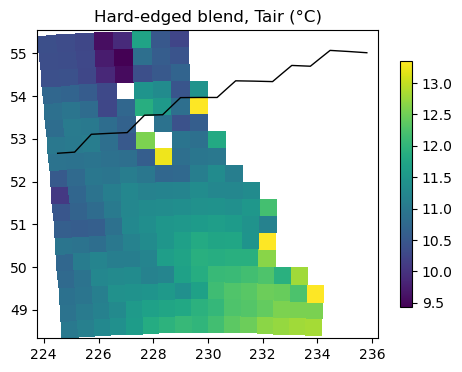

In [ ]:
tair_hard = hard["Tair"].isel(time=0).compute()
assert not bool(tair_hard.isnull().any())

fig, ax = plt.subplots(figsize=(5.5, 4))
show(ax, tair_hard, "Hard-edged blend, Tair (°C)", vmin=vmin, vmax=vmax)
ax.contour(lon, lat, covered, levels=[0.5], colors="k", linewidths=1)
plt.show()

The black line marks the edge of the CONUS404 footprint. Wherever the two products disagree, the field has a step there.

## Smoothing the seam

`blend_width_km` replaces the step with a transition band. The primary's weight ramps from 0 at the edge of its footprint to 1 at `blend_width_km` inside it, and the two products are averaged with those weights. The band width is converted to grid cells, so the blend needs the grid; when the primary is a `SurfaceForcing`, as here, its grid is used.

In [ ]:
%%time
feathered = blend_surface_forcing(conus404, era5, blend_width_km=150)
feathered.attrs["blend_method"], feathered.attrs["blend_width_km"]

2026-11-11 12:49:28 - INFO - Primary covers 77.7% of the target ocean points; the remainder comes from the fallback.


CPU times: user 21.4 s, sys: 6.2 s, total: 27.6 s
Wall time: 38.9 s


('feathered', '150.0')

`compute_blend_weights` returns the weights the blend used, so they can be inspected. It needs the footprint and the mean grid spacing in metres.

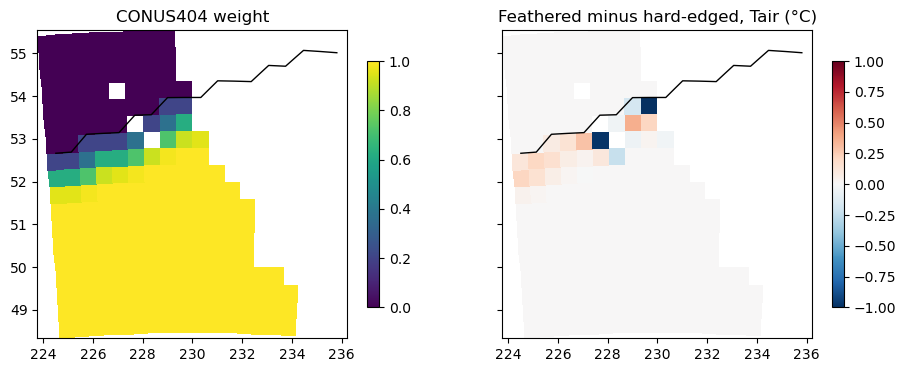

In [ ]:
cell_size_m = (float((1 / grid.ds.pn).mean()), float((1 / grid.ds.pm).mean()))
weights = compute_blend_weights(covered, cell_size_m=cell_size_m, width_km=150)

fig, axs = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
show(axs[0], weights, "CONUS404 weight", vmin=0, vmax=1, cmap="viridis")
show(
    axs[1],
    feathered["Tair"].isel(time=0) - tair_hard,
    "Feathered minus hard-edged, Tair (°C)",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
)
for ax in axs:
    ax.contour(lon, lat, covered, levels=[0.5], colors="k", linewidths=1)
plt.show()

The weight is 0 outside the footprint, so the feathered and hard-edged blends are identical there: the band lies entirely inside CONUS404's territory. That is deliberate. The outer rim of a regional model's domain is where it is nudged toward the reanalysis that drove it (CONUS404 is driven by ERA5), so using ERA5 there loses little, while spreading CONUS404 outward would extend it into places it never simulated.

### Along a line across the boundary

A south-to-north line of ocean points crosses the boundary once. Along it, the hard-edged blend jumps from the CONUS404 value to the ERA5 value; the feathered blend moves between them over about 150 km.

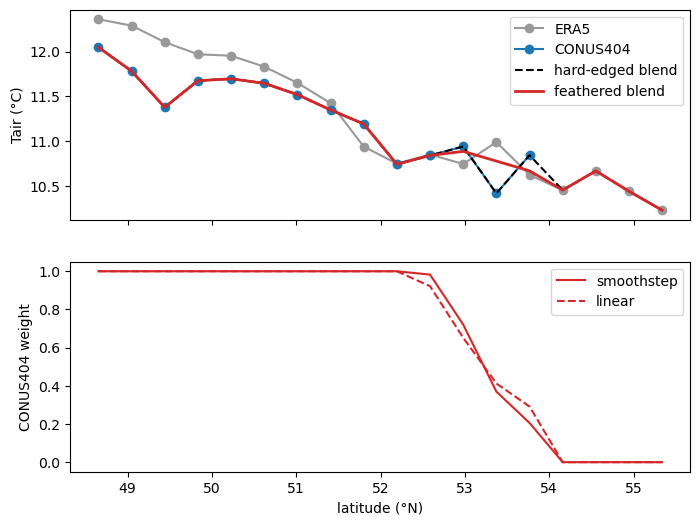

In [ ]:
j = 7  # a column that is ocean from south to north
assert bool(ocean.isel(xi_rho=j).all())
y = lat.isel(xi_rho=j)

fig, axs = plt.subplots(2, 1, figsize=(8, 6), sharex=True)
axs[0].plot(y, tair_e.isel(xi_rho=j), "o-", color="0.6", label="ERA5")
axs[0].plot(y, tair_c.isel(xi_rho=j), "o-", color="tab:blue", label="CONUS404")
axs[0].plot(y, tair_hard.isel(xi_rho=j), "k--", label="hard-edged blend")
axs[0].plot(y, feathered["Tair"].isel(time=0, xi_rho=j), color="tab:red", lw=2, label="feathered blend")
axs[0].set_ylabel("Tair (°C)")
axs[0].legend()
for profile, ls in [("smoothstep", "-"), ("linear", "--")]:
    w = compute_blend_weights(covered, cell_size_m=cell_size_m, width_km=150, profile=profile)
    axs[1].plot(y, w.isel(xi_rho=j), ls, color="tab:red", label=profile)
axs[1].set_ylabel("CONUS404 weight")
axs[1].set_xlabel("latitude (°N)")
axs[1].legend()
plt.show()

The default ramp, `blend_profile="smoothstep"`, has no kink at either end of the band. A linear ramp has a kink at each end, which shows up in quantities computed from gradients, such as wind stress curl; pass `blend_profile="linear"` if you want it anyway.

<div class="alert alert-info">

**How wide should the band be?** Of the order of 100–200 km against ERA5, a few times the coarser product's resolution. Wider does not help: once the cell next to the boundary has a weight near zero it is already pure ERA5, so a wider band only moves the transition deeper into CONUS404's territory, where CONUS404 is the better product. Measured across the real CONUS404/ERA5 boundary with bands of 0, 150, 400 and 800 km on a 40 km grid, the mean step across the boundary improved most at 150 km and then levelled off.

**What to expect.** The step across the boundary does not go to zero, and should not: what remains is the real difference between the two products plus ERA5's own weather. Feathering removes only the part caused by switching products mid-field.

</div>

## Things to keep in mind

* **Same grid and resolution.** Build both products on the same grid with the same explicit `coarse_grid_mode` (`"never"` or `"always"`). A different grid shape or `use_coarse_grid` is rejected; a different grid of the same shape is not detected.
* **Same times.** By default (`time_align="exact"`) the fallback must contain every time stamp of the primary. Products built for the same `start_time`, `end_time` and `model_reference_date` do. Otherwise pass `time_align="nearest"` (with `time_tolerance`) or `"linear"`.
* **Same variables.** Every variable of the primary must be in the fallback. A variable only the fallback has is an error by default; `on_missing_primary_var="fallback"` takes it from the fallback everywhere instead.
* **Radiation.** Each product applies its own correction before blending, so `swrad` and `lwrad` can show a larger step than other fields; the feathering smooths it along with everything else.
* **Humidity.** Both products compute `qair` from their own surface pressure. If your ERA5 extract has no pressure field (`sp` or `msl`), ROMS-Tools falls back to a fixed 1010 hPa, which adds an artificial step in `qair`; include `sp` in the download.

## Saving the result

Write the blended dataset with `save_blended_surface_forcing` (from the same module), not `to_netcdf`. It writes one file per month with the encodings ROMS needs, as `SurfaceForcing.save` does; plain `to_netcdf` would write `abs_time` as a 64-bit integer, which a ROMS build that uses ParallelIO cannot read. For a run longer than a few days, build and save each product with `SurfaceForcing.save` and blend the files month by month, as shown in [Blending saved surface-forcing files](blend_surface_forcing_files.ipynb).